,Time,Price,Forecast,Signal,Position,Cash,Eq %
39,12:47:51,58.86,58.90,HOLD,0,10183,+1.83%
40,12:48:51,59.10,59.00,OPEN SHORT,-50,13138,+1.83%
41,12:49:51,58.87,59.00,BUY LONG,50,7250,+1.94%
42,12:50:52,59.26,59.08,OPEN SHORT,-50,13177,+2.14%
43,12:51:52,59.03,58.92,HOLD,-50,13177,+2.25%
44,12:52:52,58.88,58.79,HOLD,-50,13177,+2.33%
45,12:53:52,58.89,58.79,HOLD,-50,13177,+2.32%
46,12:54:52,58.47,58.74,BUY LONG,50,7330,+2.53%
47,12:55:53,58.63,58.58,HOLD,0,10261,+2.61%
48,12:56:53,59.36,59.33,HOLD,0,10261,+2.61%



Activity:
BUY COVER @ 58.47 (-2923.42$)
OPEN LONG @ 58.47
SELL CLOSE @ 58.63 (+2931.51$)

🛑 Остановка...


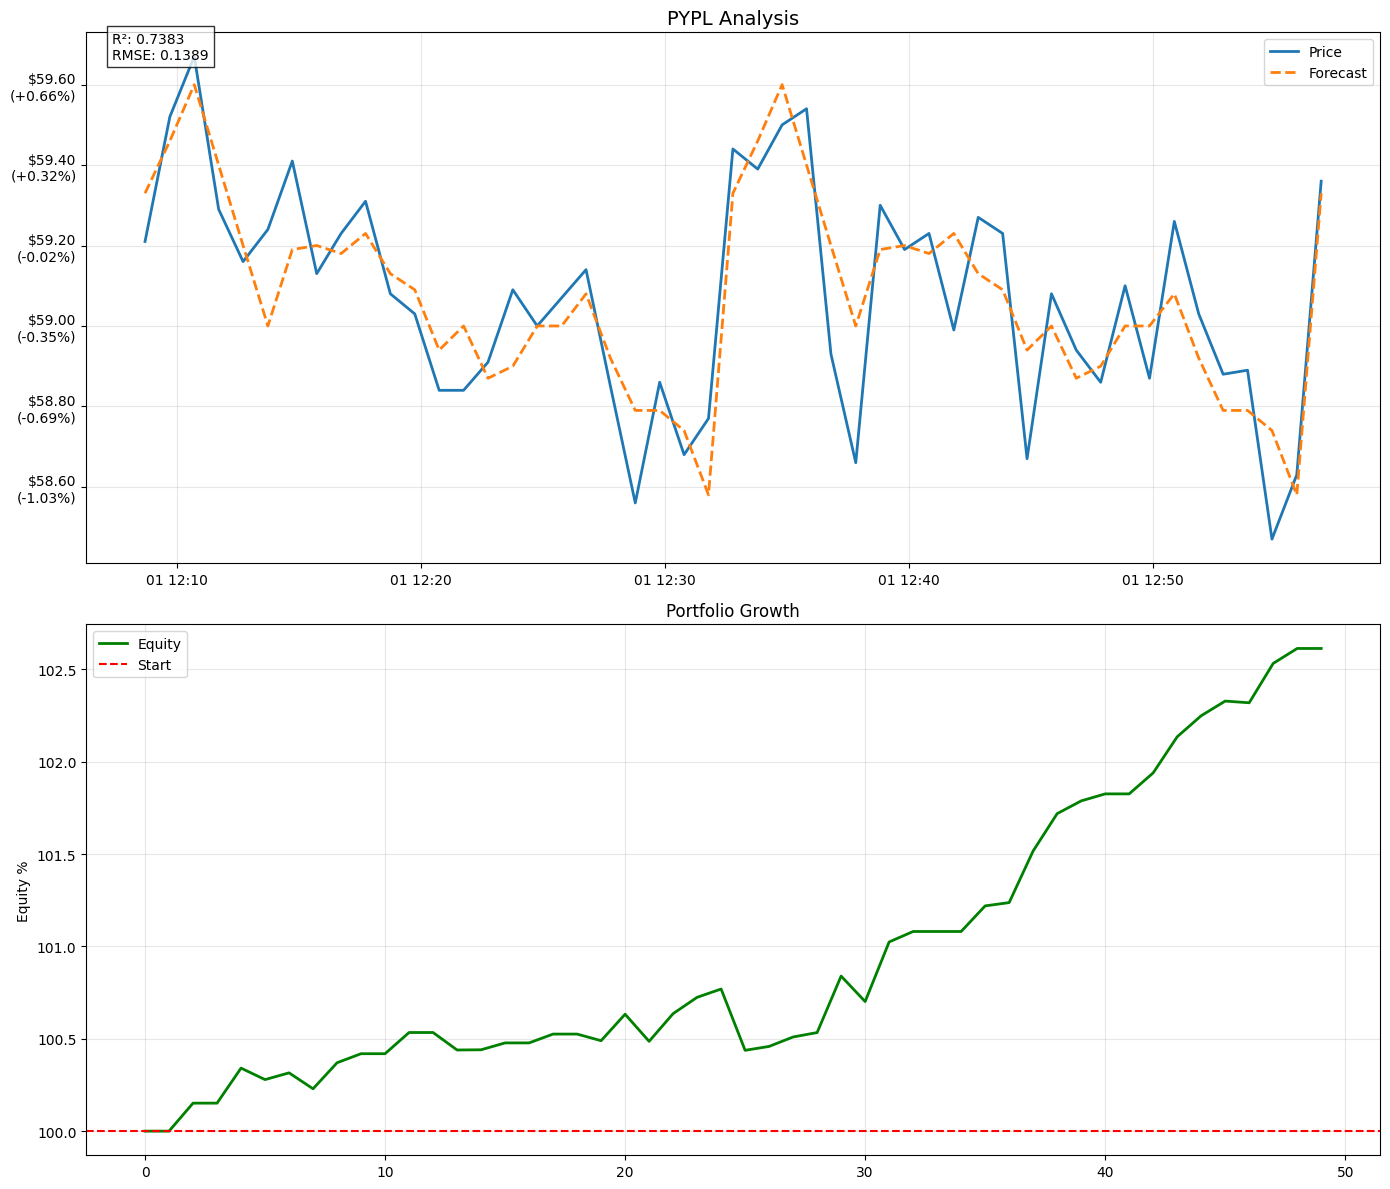

In [13]:
# --- ЯЧЕЙКА JUPYTER NOTEBOOK ---
%matplotlib inline

import pandas as pd
import numpy as np
import yfinance as yf
import time
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from datetime import datetime
from IPython.display import clear_output, display
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# ПОДКЛЮЧЕНИЕ МОДУЛЯ ML (proj_pay2.py)
# ==========================================
try:
    import proj_pay2
except ImportError:
    class MockProjPay:
        def run_training_cycle(self):
            return False
    proj_pay2 = MockProjPay()

# --- КОНФИГУРАЦИЯ ---
TICKER = "PYPL"
DATA_DIR = "future_predictions_pro"
INITIAL_CASH = 10000.0
TRADE_QUANTITY = 50 

class TradingBotEmulator:
    def __init__(self, ticker, folder):
        self.ticker = ticker
        self.folder = folder
        self.start_time = time.time()
        
        self.cash = INITIAL_CASH
        self.position = 0
        self.equity_history = [100.0]
        self.trade_log = []
        self.history = []
        
        self.deviation_strikes = 0
        self.last_generated_price = None 
        
        # Загружаем прогнозы с защитой от ошибок
        self.prediction_dfs = self._load_predictions()
        self.current_step = 0
        
    def _load_predictions(self):
        """Загружает CSV файлы и гарантирует наличие колонки 'predicted_price'."""
        if not os.path.exists(self.folder):
            os.makedirs(self.folder)
            
        files = glob.glob(os.path.join(self.folder, "*.csv"))
        
        # Если файлов нет, создаем тестовый
        if not files:
            print("⚠️ Файлов прогноза нет. Создаю тестовый файл...")
            steps = 1000
            trend = np.linspace(60, 65, steps)
            noise = np.random.normal(0, 0.2, steps)
            dummy_df = pd.DataFrame({'predicted_price': trend + noise})
            dummy_path = os.path.join(self.folder, "test_pred_init.csv")
            dummy_df.to_csv(dummy_path, index=False)
            files = [dummy_path]
            
        latest_files = sorted(files, key=os.path.getmtime, reverse=True)[:3]
        loaded_dfs = []
        
        for f in latest_files:
            try:
                df = pd.read_csv(f)
                
                # --- ЛОГИКА ИСПРАВЛЕНИЯ КОЛОНОК ---
                if 'predicted_price' not in df.columns:
                    # Если есть колонка Close, переименовываем
                    if 'Close' in df.columns:
                        df.rename(columns={'Close': 'predicted_price'}, inplace=True)
                    # Иначе просто берем ПЕРВУЮ колонку и считаем её прогнозом
                    else:
                        first_col = df.columns[0]
                        # print(f"⚠️ В файле {os.path.basename(f)} нет 'predicted_price'. Использую колонку '{first_col}'.")
                        df.rename(columns={first_col: 'predicted_price'}, inplace=True)
                
                # Принудительная конвертация в числа
                df['predicted_price'] = pd.to_numeric(df['predicted_price'], errors='coerce')
                df.dropna(subset=['predicted_price'], inplace=True)
                
                if not df.empty:
                    loaded_dfs.append(df)
                    
            except Exception as e:
                print(f"❌ Ошибка чтения файла {f}: {e}")
        
        if not loaded_dfs:
            # Аварийная заглушка, если все файлы битые
            return [pd.DataFrame({'predicted_price': [60.0]*100})]
            
        return loaded_dfs

    def _fetch_market_data_stream(self, target_forecast=None):
        time.sleep(np.random.uniform(0.1, 0.3)) 
        
        if target_forecast is None or np.isnan(target_forecast): 
            return self.last_generated_price if self.last_generated_price else 60.0
        
        noise = np.random.normal(0, target_forecast * 0.002) 
        new_price = target_forecast + noise
        self.last_generated_price = new_price
        return new_price

    def execute_trade(self, current_price, forecast_price):
        signal = "HOLD"
        threshold = 0.001 
        
        if self.position > 0 and forecast_price < current_price:
            revenue = self.position * current_price
            self.cash += revenue
            self.trade_log.append(f"SELL CLOSE @ {current_price:.2f} (+{revenue:.2f}$)")
            self.position = 0
        elif self.position < 0 and forecast_price > current_price:
            cost = abs(self.position) * current_price
            self.cash -= cost 
            self.trade_log.append(f"BUY COVER @ {current_price:.2f} (-{cost:.2f}$)")
            self.position = 0

        if self.position == 0:
            if forecast_price > current_price * (1 + threshold):
                self.position = TRADE_QUANTITY
                cost = self.position * current_price
                self.cash -= cost
                signal = "BUY LONG"
                self.trade_log.append(f"OPEN LONG @ {current_price:.2f}")
            elif forecast_price < current_price * (1 - threshold):
                self.position = -TRADE_QUANTITY
                revenue = abs(self.position) * current_price
                self.cash += revenue 
                signal = "OPEN SHORT"
                self.trade_log.append(f"OPEN SHORT @ {current_price:.2f}")
        
        return signal

    def check_market_deviation(self, price, forecast, current_equity):
        if price == 0 or np.isnan(price) or np.isnan(forecast): return
        
        deviation_pct = abs(price - forecast) / price
        
        # 1. СТОП ПРИ > 5%
        if deviation_pct >= 0.05:
            print(f"\n🛑 КРИТИЧЕСКОЕ ОТКЛОНЕНИЕ: {deviation_pct*100:.2f}% (Порог 5%)")
            print("🛑 ОСТАНОВКА БОТА.")
            raise KeyboardInterrupt 

        # 2. ПРЕДУПРЕЖДЕНИЕ ПРИ > 3%
        if deviation_pct >= 0.03:
            self.deviation_strikes += 1
            print(f"⚠️ WARN: Отклонение {deviation_pct*100:.2f}% (Strike {self.deviation_strikes}/3)")
            if self.deviation_strikes >= 3:
                 print("⚠️ Слишком много ошибок подряд. Остановка.")
                 raise KeyboardInterrupt
        else:
            if self.deviation_strikes > 0:
                self.deviation_strikes = 0

    def run(self):
        print(f"🚀 Запуск бота {self.ticker}. Safe Mode: ON.")
        
        try:
            while True:
                # 1. Получаем прогноз
                raw_preds = []
                for df in self.prediction_dfs:
                    if len(df) > 0:
                        idx = self.current_step % len(df)
                        # Теперь колонка точно называется predicted_price
                        val = df['predicted_price'].iloc[idx]
                        if not np.isnan(val):
                            raw_preds.append(val)
                
                if not raw_preds:
                    current_forecast = 60.0
                else:
                    current_forecast = np.mean(raw_preds)
                
                # 2. Эмулируем рынок
                price = self._fetch_market_data_stream(target_forecast=current_forecast)
                
                # 3. Баланс
                current_equity_val = self.cash + (self.position * price)
                
                # 4. Проверка безопасности
                self.check_market_deviation(price, current_forecast, current_equity_val)
                
                # 5. Торговля
                signal = self.execute_trade(price, current_forecast)
                
                # Запись истории
                current_equity_val = self.cash + (self.position * price)
                equity_pct_total = ((current_equity_val - INITIAL_CASH) / INITIAL_CASH) * 100
                portfolio_pct_val = 100 + equity_pct_total 
                
                self.equity_history.append(portfolio_pct_val)
                self.history.append({
                    'Time': datetime.now().strftime('%H:%M:%S'),
                    'Price': round(price, 2),
                    'Forecast': round(current_forecast, 2),
                    'Signal': signal,
                    'Position': self.position,
                    'Cash': f"{self.cash:.0f}",
                    'Eq %': f"{equity_pct_total:+.2f}%"
                })

                # Интерфейс
                clear_output(wait=True) 
                elapsed = (time.time() - self.start_time) / 60
                
                print(f"=== {self.ticker} SAFE TRADING BOT ===")
                print(f"Time: {datetime.now().strftime('%H:%M:%S')} | Run Time: {int(elapsed)} min")
                print(f"Stop condition: Deviation > 5%")
                
                display(pd.DataFrame(self.history).tail(10))
                
                if self.trade_log:
                    print(f"\nActivity:\n" + "\n".join(self.trade_log[-3:]))
                
                self.current_step += 1
                time.sleep(60) 

        except KeyboardInterrupt:
            print("\n🛑 Остановка...")
            self.show_final_report()
        except Exception as e:
            print(f"\n❌ Критическая ошибка: {e}")
            import traceback
            traceback.print_exc()

    def show_final_report(self):
        df = pd.DataFrame(self.history)
        
        if len(df) < 2:
            print("Недостаточно данных для отчета.")
            return

        # Очистка данных
        df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
        df['Forecast'] = pd.to_numeric(df['Forecast'], errors='coerce')
        df.dropna(subset=['Price', 'Forecast'], inplace=True)
        
        if len(df) < 2: return

        actual = df['Price'].values
        forecast = df['Forecast'].values
        initial_price = actual[0]
        
        rmse = np.sqrt(mean_squared_error(actual, forecast))
        r2 = r2_score(actual, forecast)

        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))
        
        # График 1
        ax1.plot(pd.to_datetime(df['Time'], format='%H:%M:%S'), df['Price'], label='Price', color='#1f77b4', linewidth=2)
        ax1.plot(pd.to_datetime(df['Time'], format='%H:%M:%S'), df['Forecast'], label='Forecast', color='#ff7f0e', linestyle='--', linewidth=2)
        
        def price_percent_fmt(x, pos):
            pct_change = ((x - initial_price) / initial_price) * 100
            return f"${x:.2f}\n({pct_change:+.2f}%)"

        ax1.yaxis.set_major_formatter(mtick.FuncFormatter(price_percent_fmt))
        ax1.set_title(f"{self.ticker} Analysis", fontsize=14)
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        ax1.text(0.02, 0.95, f"R²: {r2:.4f}\nRMSE: {rmse:.4f}", transform=ax1.transAxes, bbox=dict(facecolor='white', alpha=0.8))

        # График 2
        ax2.plot(self.equity_history, color='green', linewidth=2, label='Equity')
        ax2.axhline(100, color='red', linestyle='--', label='Start')
        ax2.set_title("Portfolio Growth")
        ax2.set_ylabel("Equity %")
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    if not os.path.exists(DATA_DIR): os.makedirs(DATA_DIR)
    bot = TradingBotEmulator(TICKER, DATA_DIR)
    bot.run()